# 05 · Modelos de predicción de nivel · La Lindosa

**Entrada:** `data/clean/La_Lindosa/La_Lindosa_horario_limpio.csv` (notebook 03).
**Salida:** `models/La_Lindosa/metricas_prueba_2025.csv` (tabla de errores de cada modelo).

**Objetivo:** entrenar cuatro modelos que predicen el **nivel del río en La Lindosa unas horas hacia adelante**, evaluarlos con los mismos datos y decidir cuál conviene usar en esta estación.

Los cuatro modelos, de lo más simple a lo más complejo:

| Modelo | Tipo | Idea en una frase |
|---|---|---|
| **SARIMAX** | Estadístico clásico | El nivel de la próxima hora se parece al de las horas anteriores, más un efecto de la lluvia acumulada. |
| **XGBoost** | Árboles de decisión (*machine learning*) | Muchos árboles pequeños aprenden reglas del tipo "si llovió más de X mm en 6 h y el río ya viene subiendo, sube Y cm". |
| **LSTM** | Red neuronal para series de tiempo (*deep learning*) | Lee las últimas 72 horas, hora por hora, y aprende sola qué patrones anuncian una subida. |
| **Prophet** | Descomposición en tendencia + ciclos | Explica el nivel con una tendencia lenta, un ciclo anual (temporadas de lluvia) y un ciclo diario. |

Además se usa una **referencia** que no es un modelo: la **persistencia**, que predice que dentro de *h* horas el nivel será igual al de ahora. Parece ingenua, pero en un río que cambia despacio es difícil de superar a pocas horas. **Un modelo solo vale la pena si le gana a la persistencia.**

Contenido:

1. Configuración y carga de datos
2. Horizonte de predicción y partición entrenamiento / validación / prueba
3. Cómo se evalúa (métricas y horas que se usan)
4. Modelo 1: SARIMAX
5. Modelo 2: XGBoost
6. Modelo 3: LSTM
7. Modelo 4: Prophet
8. Comparación final y modelo recomendado
9. Conclusiones

> **Tiempo de ejecución:** unos 5 a 8 minutos en un computador normal (la mayor parte es Prophet y la LSTM). Las librerías necesarias están en `notebooks/README.md`.

## 1. Configuración y carga de datos

Todos los parámetros que se pueden cambiar están en la siguiente celda. El notebook es igual para las dos estaciones: el de la otra estación solo cambia `ESTACION`.

**Qué datos se usan:**

- **Nivel:** solo las horas con calidad `REAL` u `ALTA`. Las horas `MEDIA` (relleno con el promedio histórico) se dejan **vacías**: no son el río real, y si el modelo las aprendiera estaría aprendiendo el método de relleno. Las filas no se borran, para no pegar horas separadas por un hueco; en cambio, se descartan las muestras que necesiten una hora vacía.
- **Lluvia:** la columna final (con imputados), igual que en el notebook 04, porque la lluvia acumulada de varias horas necesita todas las horas.
- **Temperatura:** no se usa. El notebook 04 mostró que casi no se relaciona con el nivel (|r| < 0,15).

In [1]:
import logging
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)

# ---------------- Parámetros ----------------
ESTACION = "La_Lindosa"
HORIZONTES = [1, 3, 6, 12]      # horas hacia adelante que se evalúan
H_PRINCIPAL = 6                 # horizonte con el que se elige el mejor modelo
FIN_TRAIN = "2023-12-31 23:00"  # entrenamiento: 2018-2023
INI_VAL, FIN_VAL = "2024-01-01", "2024-12-31 23:00"  # validación: 2024
INI_TEST = "2025-01-01"         # prueba: 2025 (los modelos nunca la ven al entrenar)
VENTANA = 72                    # horas de historia que lee la LSTM
ACUMULADOS = [1, 3, 6, 12, 24, 72, 168]  # ventanas de lluvia acumulada (h)
SEMILLA = 42                    # para que los resultados se puedan repetir
# --------------------------------------------

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
NOMBRE = {"La_Lindosa": "La Lindosa", "Los_Micos": "Los Micos"}[ESTACION]
H_MAX = max(HORIZONTES)
COLORES = {"Persistencia": "#adb5bd", "SARIMAX": "#457b9d", "XGBoost": "#2a9d8f", "LSTM": "#e76f51", "Prophet": "#9b5de5"}
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.3f}".format)
np.random.seed(SEMILLA)

df = pd.read_csv(RAIZ / "data" / "clean" / ESTACION / f"{ESTACION}_horario_limpio.csv",
                 parse_dates=["fecha_hora"], index_col="fecha_hora").asfreq("h")
nivel = df.nivel_m.where(df.nivel_m_calidad.isin(["REAL", "ALTA"]))  # MEDIA -> vacío
lluvia = df.lluvia_mm
lluvia_acum = pd.DataFrame({f"lluvia_{w}h": lluvia.rolling(w, min_periods=1).sum() for w in ACUMULADOS})

print(f"{NOMBRE}: {len(df):,} horas, {df.index.min():%Y-%m-%d %H:%M} a {df.index.max():%Y-%m-%d %H:%M}")
print(f"Horas de nivel utilizables (REAL o ALTA): {nivel.notna().mean():.1%}")

La Lindosa: 74,726 horas, 2017-06-23 10:00 a 2025-12-31 23:00
Horas de nivel utilizables (REAL o ALTA): 94.1%


## 2. Horizonte de predicción y partición de los datos

### 2.1 ¿Cuántas horas hacia adelante predecir?

Se evalúan cuatro horizontes, **1, 3, 6 y 12 horas**, y el modelo recomendado se elige con el de **6 horas**. La razón:

- El notebook 04 mostró que el río responde a la lluvia **muy rápido** (0 a 1 hora entre la lluvia y la subida). Eso quiere decir que, sin un pronóstico de lluvia, ningún modelo puede "ver venir" una crecida causada por una lluvia que todavía no ha caído.
- A **1 hora** casi cualquier método acierta (el río no cambia mucho en una hora), pero un aviso con una hora de anticipación sirve poco para una alerta temprana.
- A **6 horas** todavía hay información útil (el río que ya viene subiendo, la lluvia de las últimas horas y días, la hora del día) y el aviso da tiempo para reaccionar. Es un punto de equilibrio razonable entre utilidad y precisión.
- A **12 horas** se muestra para ver hasta dónde llega cada modelo; ahí ya pesa mucho la lluvia futura, que los modelos no conocen.

Si más adelante se agrega un pronóstico de lluvia (por ejemplo de IDEAM), tendría sentido evaluar horizontes más largos.

**Regla importante:** para predecir el nivel de las *t + h* horas, cada modelo usa **solo información disponible hasta la hora *t*** (nivel y lluvia observados hasta ese momento). Nada del futuro.

### 2.2 Entrenamiento, validación y prueba

Las series de tiempo **no** se parten al azar: si el modelo viera horas de 2025 al entrenar, la prueba sería tramposa. Se parte por fechas:

| Conjunto | Años | Para qué se usa |
|---|---|---|
| Entrenamiento | 2018-2023 | El modelo aprende de estos datos (se deja fuera 2017 porque es un año incompleto con mucho relleno). |
| Validación | 2024 | Elegir ajustes del modelo y saber cuándo parar de entrenar (XGBoost y LSTM). |
| Prueba | 2025 | **Solo** para medir el error final. Es el "examen" que ningún modelo vio antes. |

**Cuidado con el nivel de base:** el notebook 04 encontró que el nivel "de fondo" cambia entre años (La Lindosa baja de ~0,85 m en 2018-2022 a ~0,70 m en 2023-2024 y ~0,59 m en 2025). Un modelo que aprenda el **nivel absoluto** de 2018-2023 se equivocará en 2025 aunque haya entendido bien cómo responde el río. Por eso, SARIMAX, XGBoost y LSTM se plantean para predecir **el cambio de nivel** respecto al nivel actual, que no depende del nivel de base. Prophet, por cómo está construido, predice el nivel absoluto; eso se verá en sus resultados.

,desde,hasta,horas,% nivel utilizable,nivel mediano (m)
excluido,2017-06-23,2017-12-31,4598,63.897,0.780
entrenamiento,2018-01-01,2023-12-31,52584,96.788,0.840
validación,2024-01-01,2024-12-31,8784,95.856,0.699
prueba,2025-01-01,2025-12-31,8760,92.123,0.586


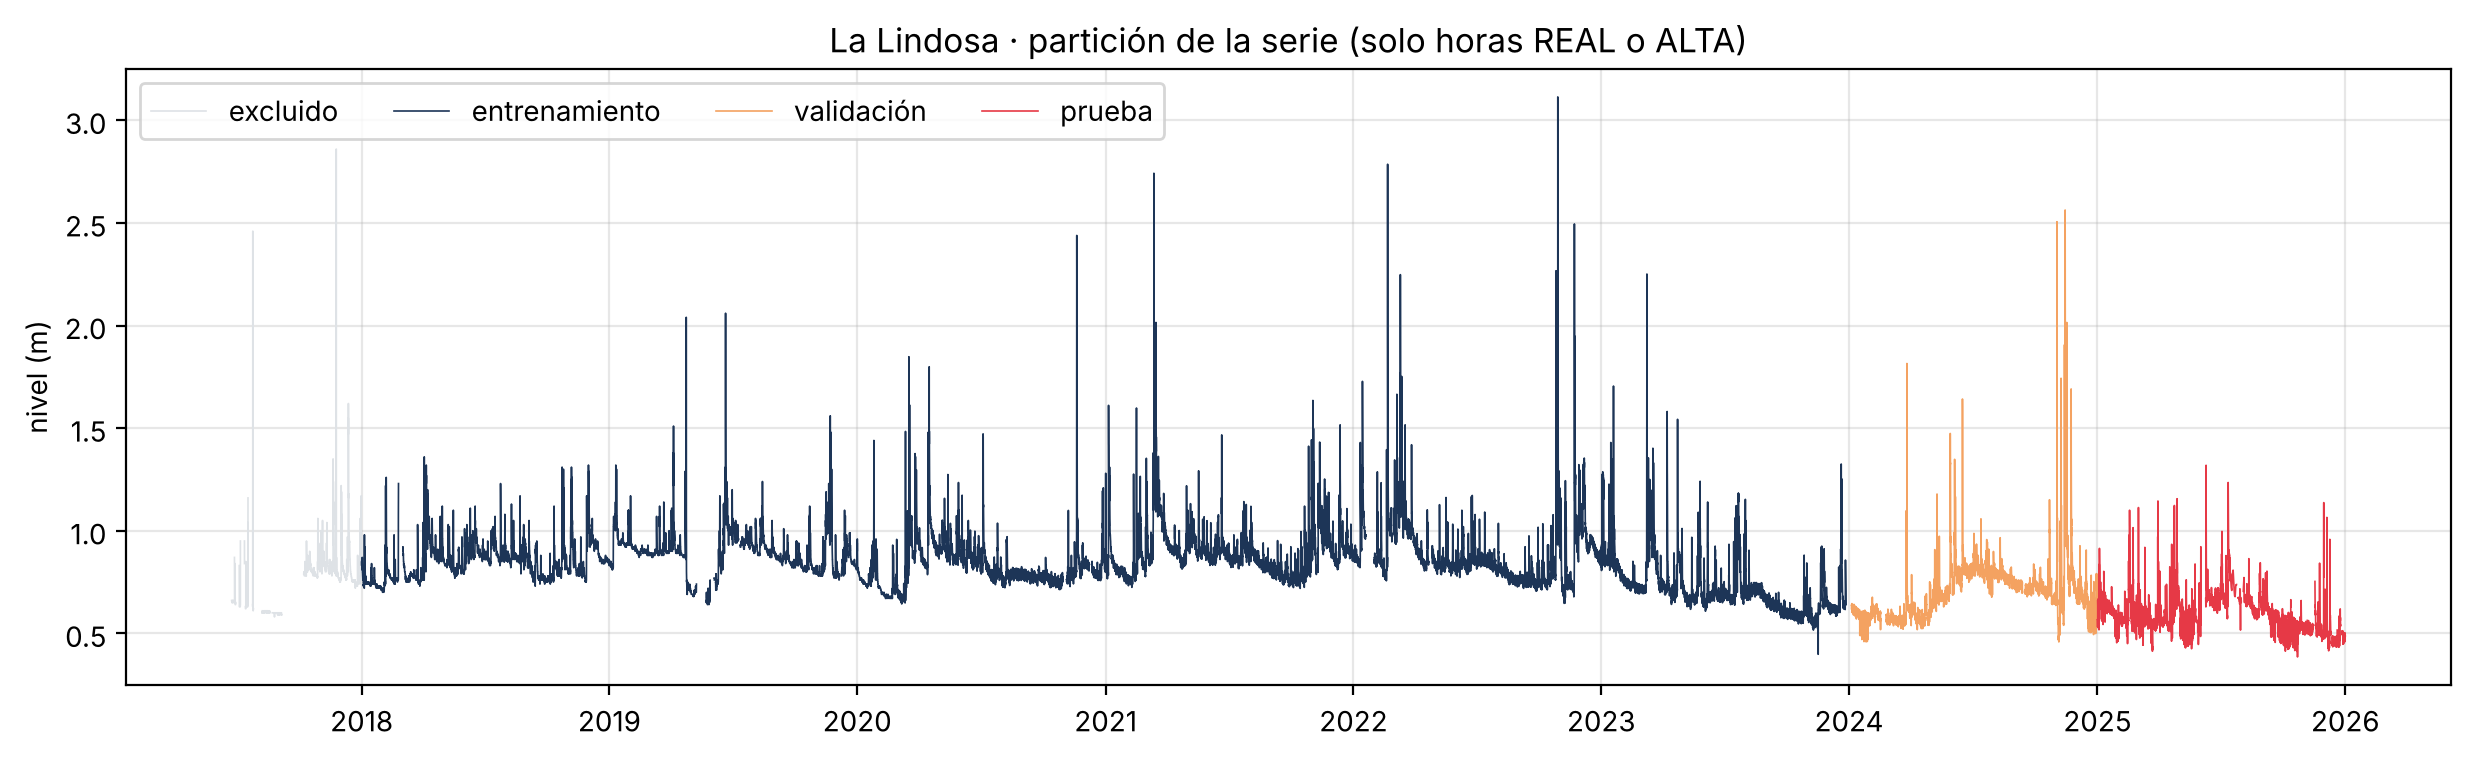

In [2]:
periodo = pd.Series("excluido", index=df.index)
periodo["2018-01-01":FIN_TRAIN] = "entrenamiento"
periodo[INI_VAL:FIN_VAL] = "validación"
periodo[INI_TEST:] = "prueba"

resumen = pd.DataFrame({
    "desde": df.index.to_series().groupby(periodo).min().dt.strftime("%Y-%m-%d"),
    "hasta": df.index.to_series().groupby(periodo).max().dt.strftime("%Y-%m-%d"),
    "horas": periodo.value_counts(),
    "% nivel utilizable": nivel.notna().groupby(periodo).mean() * 100,
    "nivel mediano (m)": nivel.groupby(periodo).median(),
}).loc[["excluido", "entrenamiento", "validación", "prueba"]]
display(resumen)

fig, ax = plt.subplots(figsize=(15, 4))
for p, c in [("excluido", "#dee2e6"), ("entrenamiento", "#1d3557"), ("validación", "#f4a261"), ("prueba", "#e63946")]:
    ax.plot(nivel.where(periodo == p), color=c, lw=0.6, label=p)
ax.set_ylabel("nivel (m)")
ax.set_title(f"{NOMBRE} · partición de la serie (solo horas REAL o ALTA)")
ax.legend(loc="upper left", ncol=4)
plt.show()

## 3. Cómo se evalúa

### 3.1 Las mismas horas para todos

Para que la comparación sea justa, todos los modelos se evalúan **exactamente en las mismas horas de 2025**. Una hora *t* entra en la evaluación del horizonte *h* si:

- el nivel en *t* y en *t + h* es confiable (REAL o ALTA), y
- las 72 horas anteriores a *t* también tienen nivel confiable, lluvia y nivel de base de 7 días (lo necesita la LSTM; se exige a todos para usar las mismas horas).

La función de métricas verifica además que todos los modelos tengan predicción en cada hora evaluada; si faltara alguna, se detiene con un error en vez de calcular métricas con muestras distintas.

### 3.2 Métricas

| Métrica | Qué mide | Mejor valor |
|---|---|---|
| **RMSE** (cm) | Error típico. Castiga mucho los errores grandes, que son los que importan en una crecida. | 0 |
| **MAE** (cm) | Error promedio en valor absoluto. Más fácil de interpretar: "en promedio se equivoca X cm". | 0 |
| **NSE** (Nash-Sutcliffe) | Métrica estándar en hidrología. 1 = perfecto; 0 = igual que predecir siempre el promedio; negativo = peor que eso. | 1 |
| **Mejora sobre persistencia** (%) | Cuánto baja el RMSE frente a "el nivel no cambia". 0 % = no aporta nada; negativo = es peor que no hacer nada. | lo más alto posible |
| **RMSE en nivel alto** (cm) | RMSE solo en las horas en que el nivel real supera el percentil 95 de 2025. Mide el desempeño en **crecidas**, lo más importante para una alerta. | 0 |

In [3]:
# Ventana de 72 h completa antes de cada hora: nivel, lluvia y nivel de base de 7 días (lo que necesita la LSTM)
base_7d = nivel.rolling(168, min_periods=24).min()
completo = nivel.notna() & lluvia.notna()
ventana_ok = completo.rolling(VENTANA, min_periods=VENTANA).sum().eq(VENTANA)
entradas_completas = (completo & base_7d.notna()).rolling(VENTANA, min_periods=VENTANA).sum().eq(VENTANA)

# Nivel real que se quiere predecir: columna h = nivel en t + h, indexado por la hora de origen t
real = pd.DataFrame({h: nivel.shift(-h) for h in range(1, H_MAX + 1)})
evaluar = {h: (periodo == "prueba") & entradas_completas & real[h].notna() for h in HORIZONTES}
P95_PRUEBA = nivel[periodo == "prueba"].quantile(0.95)

# Aquí se guardan las predicciones de todos los modelos: pred[modelo][h] = nivel predicho para t + h
pred = {"Persistencia": pd.DataFrame({h: nivel for h in HORIZONTES})}

def tabla_metricas(nombres=None):
    filas = []
    for h in HORIZONTES:
        for alto in (False, True):
            m = evaluar[h] & (real[h] > P95_PRUEBA) if alto else evaluar[h]
            obs = real[h][m]
            for nombre in (nombres or pred):
                assert pred[nombre][h][m].notna().all(), f"{nombre} no tiene predicción en todas las horas evaluadas"
                e = pred[nombre][h][m] - obs
                filas.append({"modelo": nombre, "h": h, "subconjunto": "nivel alto" if alto else "todas",
                              "n": len(obs), "RMSE_cm": 100 * np.sqrt((e ** 2).mean()),
                              "MAE_cm": 100 * e.abs().mean(),
                              "NSE": 1 - (e ** 2).sum() / ((obs - obs.mean()) ** 2).sum()})
    t = pd.DataFrame(filas)
    base = t[t.modelo == "Persistencia"][["h", "subconjunto", "RMSE_cm"]].rename(columns={"RMSE_cm": "base"})
    t = t.merge(base, on=["h", "subconjunto"])
    t["mejora_vs_persistencia_%"] = 100 * (1 - t.RMSE_cm / t.base)
    return t.drop(columns="base")

def resumen_modelo(nombre):
    t = tabla_metricas(list(dict.fromkeys(["Persistencia", nombre])))
    t = t[t.subconjunto == "todas"].pivot(index="modelo", columns="h", values=["RMSE_cm", "NSE", "mejora_vs_persistencia_%"])
    return t.round(2)

print(f"Horas evaluadas en 2025: " + ", ".join(f"h={h}: {evaluar[h].sum():,}" for h in HORIZONTES))
print(f"Percentil 95 del nivel en 2025 (umbral de 'nivel alto'): {P95_PRUEBA:.2f} m")
display(resumen_modelo("Persistencia"))

Horas evaluadas en 2025: h=1: 6,970, h=3: 6,940, h=6: 6,895, h=12: 6,805
Percentil 95 del nivel en 2025 (umbral de 'nivel alto'): 0.76 m


RMSE_cm                     NSE                    \
h                 1     3     6     12    1     3     6     12   
modelo                                                           
Persistencia   2.930 5.230 6.890 8.350 0.900 0.690 0.460 0.210   

             mejora_vs_persistencia_%                    
h                                  1     3     6     12  
modelo                                                   
Persistencia                    0.000 0.000 0.000 0.000

**Lectura:** la tabla anterior es la **línea base**. Con la persistencia el error crece con el horizonte, porque mientras más tiempo pasa, más puede cambiar el río. Los cuatro modelos tienen que bajar estos números.

## 4. Modelo 1: SARIMAX

### ¿Qué es?

**SARIMAX** = *Seasonal AutoRegressive Integrated Moving Average with eXogenous variables*. Por partes:

- **AR (autorregresivo, orden *p*):** el cambio de nivel de esta hora depende de los cambios de las *p* horas anteriores.
- **I (integrado, orden *d* = 1):** el modelo trabaja con el **cambio** de nivel (nivel ahora − nivel hace una hora), no con el nivel. Eso lo hace inmune a los saltos del nivel de base.
- **MA (media móvil, orden *q*):** corrige con los errores de predicción de las *q* horas anteriores.
- **X (variables externas):** la lluvia acumulada de 6, 24 y 72 horas.
- **S (estacional):** el ciclo de 24 horas. En vez de la parte estacional clásica (que con un periodo de 24 haría el modelo muy lento con 50.000 horas), se agregan dos variables con el seno y el coseno de la hora del día. Es la forma recomendada para periodos largos y cumple la misma función.

### Cómo se entrena y cómo predice

1. Se prueban varios órdenes (*p*, 1, *q*) con los datos de entrenamiento y se elige el de menor **AIC** (criterio que premia el buen ajuste y castiga la complejidad).
2. Con los parámetros fijos, el modelo recorre toda la serie hora a hora (filtro de Kalman). En cada hora *t* "sabe" lo observado hasta *t* y proyecta las siguientes 12 horas. Las horas vacías (MEDIA) no le molestan: el filtro de Kalman las salta.
3. **Lluvia futura:** para predecir *t + h* el modelo necesitaría la lluvia acumulada en *t + h*, que incluye lluvia que todavía no cae. Como no hay pronóstico de lluvia, se supone **que no llueve más** después de *t*: la lluvia acumulada futura se calcula solo con la lluvia ya observada.

In [4]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

EXOG = ["lluvia_6h", "lluvia_24h", "lluvia_72h"]

def exog_sarimax(idx):
    X = lluvia_acum.loc[idx, EXOG].copy()
    X["sin_hora"] = np.sin(2 * np.pi * idx.hour / 24)
    X["cos_hora"] = np.cos(2 * np.pi * idx.hour / 24)
    return X

idx_train = df.index[periodo == "entrenamiento"]
inicio = time.time()
candidatos = []
for orden in [(1, 1, 0), (2, 1, 0), (3, 1, 0), (1, 1, 1), (2, 1, 1)]:
    ajuste = SARIMAX(nivel[idx_train], exog=exog_sarimax(idx_train), order=orden).fit(disp=False, maxiter=200)
    candidatos.append({"orden (p,d,q)": str(orden), "AIC": ajuste.aic, "ajuste": ajuste})
tabla_aic = pd.DataFrame(candidatos).sort_values("AIC")
display(tabla_aic[["orden (p,d,q)", "AIC"]])
sarimax = tabla_aic.iloc[0]["ajuste"]
print(f"Orden elegido: {tabla_aic.iloc[0]['orden (p,d,q)']} · tiempo: {time.time() - inicio:.0f} s")
display(sarimax.summary().tables[1])

,"orden (p,d,q)",AIC
4,"(2, 1, 1)","-223,412.547"
2,"(3, 1, 0)","-223,374.462"
1,"(2, 1, 0)","-223,344.904"
3,"(1, 1, 1)","-223,211.566"
0,"(1, 1, 0)","-222,874.033"


Orden elegido: (2, 1, 1) · tiempo: 39 s


,coef,std err,z,P>|z|,[0.025,0.975]
lluvia_6h,0.0020,4.58e-05,44.654,0.000,0.002,0.002
lluvia_24h,0.0014,4.98e-05,27.876,0.000,0.001,0.001
lluvia_72h,0.0012,4.97e-05,23.202,0.000,0.001,0.001
sin_hora,0.0065,0.001,8.785,0.000,0.005,0.008
cos_hora,0.0078,0.001,10.496,0.000,0.006,0.009
ar.L1,0.4317,0.007,58.287,0.000,0.417,0.446
ar.L2,-0.1413,0.001,-122.491,0.000,-0.144,-0.139
ma.L1,-0.2713,0.007,-36.786,0.000,-0.286,-0.257
sigma2,0.0007,3.98e-07,1820.997,0.000,0.001,0.001


**Cómo leer los coeficientes:** `lluvia_6h`, `lluvia_24h` y `lluvia_72h` dicen cuántos metros sube el nivel por cada mm de lluvia acumulada en esa ventana; `ar.L1`, `ar.L2`... dicen cuánto "arrastra" el cambio de nivel de la hora anterior; `sigma2` es la varianza del error de una hora. La columna `P>|z|` menor a 0,05 indica que el coeficiente es estadísticamente distinto de cero.

En La Lindosa el orden elegido es (2, 1, 1). Los tres coeficientes de lluvia son positivos y significativos: por cada mm de lluvia acumulada en 6 h el nivel sube unos 2 mm, y algo menos por la de 24 h y 72 h. Son efectos pequeños porque la mayor parte del tiempo la lluvia no mueve el río, y un modelo lineal promedia esas horas con las pocas en que sí lo mueve mucho.

Ahora se generan las predicciones. En lugar de reajustar el modelo en cada una de las ~8.700 horas de 2025 (muy lento), se usa el estado del filtro de Kalman en cada hora y se proyecta hacia adelante con las mismas ecuaciones del modelo. El resultado es idéntico al de `forecast()` de statsmodels (se verifica en la celda) pero toma segundos.

In [5]:
# Filtrar toda la serie con los parámetros ya estimados
filtrado = sarimax.apply(nivel, exog=exog_sarimax(df.index)).filter_results
estado = filtrado.filtered_state           # estado del modelo en cada hora, con lo observado hasta esa hora
T = filtrado.transition[:, :, 0]           # cómo avanza el estado una hora
Z = filtrado.design[0, :, 0]               # cómo se lee el nivel desde el estado
beta = sarimax.params[exog_sarimax(df.index[:1]).columns].values

# Lluvia acumulada futura suponiendo que no llueve después de t: suma de la lluvia en (t+k-w, t]
C = lluvia.fillna(0).cumsum().values
n, horas = len(df), df.index.hour.values

def acumulado_futuro(w, k):
    desde = np.arange(n) + k - w
    suma = C - np.where(desde >= 0, C[np.clip(desde, 0, n - 1)], 0.0)
    return suma if k < w else np.zeros(n)

pred_sar, Tk = {}, np.eye(T.shape[0])
for k in range(1, H_MAX + 1):
    Tk = T @ Tk
    hk = (horas + k) % 24
    X_fut = np.column_stack([acumulado_futuro(int(c.split("_")[1][:-1]), k) for c in EXOG]
                            + [np.sin(2 * np.pi * hk / 24), np.cos(2 * np.pi * hk / 24)])
    pred_sar[k] = (Z @ Tk) @ estado + X_fut @ beta
pred["SARIMAX"] = pd.DataFrame({h: pred_sar[h] for h in HORIZONTES}, index=df.index)

# Verificación contra statsmodels en una hora cualquiera de 2025
t0 = df.index.get_loc(evaluar[H_MAX][evaluar[H_MAX]].index[1000])
parcial = sarimax.apply(nivel.iloc[:t0 + 1], exog=exog_sarimax(df.index[:t0 + 1]))
X_ver = exog_sarimax(df.index[t0 + 1:t0 + 1 + H_MAX])
for j in range(H_MAX):
    for c in EXOG:
        X_ver.iloc[j, X_ver.columns.get_loc(c)] = acumulado_futuro(int(c.split("_")[1][:-1]), j + 1)[t0]
dif = np.abs(parcial.forecast(H_MAX, exog=X_ver).values - np.array([pred_sar[k][t0] for k in range(1, H_MAX + 1)])).max()
print(f"Diferencia máxima con statsmodels.forecast(): {dif:.1e} m (debe ser ~0)")

display(resumen_modelo("SARIMAX"))

Diferencia máxima con statsmodels.forecast(): 1.1e-16 m (debe ser ~0)


RMSE_cm                     NSE                    \
h                 1     3     6     12    1     3     6     12   
modelo                                                           
Persistencia   2.930 5.230 6.890 8.350 0.900 0.690 0.460 0.210   
SARIMAX        2.910 5.240 6.890 8.300 0.900 0.690 0.460 0.220   

             mejora_vs_persistencia_%                      
h                                  1      3      6     12  
modelo                                                     
Persistencia                    0.000  0.000  0.000 0.000  
SARIMAX                         0.650 -0.160 -0.010 0.620

**Lectura:** SARIMAX queda **prácticamente empatado con la persistencia** en todos los horizontes (a 6 h, 6,88 cm frente a 6,88 cm) y es algo peor en nivel alto. Es decir, en La Lindosa no aporta información útil más allá de "el nivel sigue igual". La razón probable: es un modelo **lineal** y la respuesta del río a la lluvia no lo es (la misma lluvia mueve mucho el río en temporada de lluvias y casi nada en sequía), y la hipótesis de "no llueve más" le quita lo que podría ganar con la lluvia.

## 5. Modelo 2: XGBoost

### ¿Qué es?

**XGBoost** (*eXtreme Gradient Boosting*) construye cientos de **árboles de decisión** pequeños, uno tras otro. Cada árbol nuevo intenta corregir los errores que dejaron los anteriores. Es de los métodos que mejor funcionan con datos en forma de tabla, es rápido, maneja solo los valores vacíos y permite ver qué variables pesan más.

A diferencia de SARIMAX y la LSTM, XGBoost no "lee" la serie: hay que darle, para cada hora *t*, una fila con **atributos** que resuman lo que ha pasado hasta *t*.

### Atributos (todo calculado con información hasta la hora *t*)

| Atributo | Qué representa |
|---|---|
| `nivel_sobre_base7d` | Nivel actual menos el mínimo de los últimos 7 días: qué tan "crecido" está el río respecto a su base reciente. Se usa en vez del nivel absoluto para no depender de los saltos del nivel de base. |
| `cambio_1h` ... `cambio_24h` | Cuánto cambió el nivel en la última 1, 2, 3, 6, 12 y 24 h: si el río viene subiendo o bajando, y qué tan rápido. |
| `lluvia_1h` ... `lluvia_168h` | Lluvia acumulada en las últimas 1, 3, 6, 12, 24, 72 y 168 h (el notebook 04 mostró que la lluvia acumulada de varios días es la que más se relaciona con el nivel). |
| `sin_hora`, `cos_hora` | Hora del día (ciclo diario), escrita como seno y coseno para que las 23:00 queden "cerca" de las 00:00. |
| `sin_dia`, `cos_dia` | Día del año (temporadas de lluvia y sequía), con la misma idea. |

**Objetivo:** el **cambio** de nivel entre *t* y *t + h*. La predicción final es *nivel(t) + cambio predicho*. Se entrena **un modelo por horizonte**.

**Parada temprana:** se agregan árboles mientras el error en **validación (2024)** siga bajando; si en 100 árboles seguidos no mejora, se detiene. Así se evita que el modelo memorice el entrenamiento (sobreajuste).

In [6]:
import xgboost as xgb

atributos = pd.DataFrame({"nivel_sobre_base7d": nivel - base_7d}, index=df.index)
for k in [1, 2, 3, 6, 12, 24]:
    atributos[f"cambio_{k}h"] = nivel - nivel.shift(k)
atributos = atributos.join(lluvia_acum)
atributos["sin_hora"] = np.sin(2 * np.pi * df.index.hour / 24)
atributos["cos_hora"] = np.cos(2 * np.pi * df.index.hour / 24)
atributos["sin_dia"] = np.sin(2 * np.pi * df.index.dayofyear / 365.25)
atributos["cos_dia"] = np.cos(2 * np.pi * df.index.dayofyear / 365.25)

modelos_xgb, pred_xgb, inicio = {}, {}, time.time()
for h in HORIZONTES:
    objetivo = nivel.shift(-h) - nivel
    usable = objetivo.notna() & nivel.notna()
    ent, val = usable & (periodo == "entrenamiento"), usable & (periodo == "validación")
    modelo = xgb.XGBRegressor(n_estimators=3000, learning_rate=0.03, max_depth=6, min_child_weight=5,
                              subsample=0.8, colsample_bytree=0.8, early_stopping_rounds=100,
                              random_state=SEMILLA, n_jobs=-1)
    modelo.fit(atributos[ent], objetivo[ent], eval_set=[(atributos[val], objetivo[val])], verbose=False)
    modelos_xgb[h] = modelo
    pred_xgb[h] = nivel + modelo.predict(atributos)
    print(f"h = {h:>2} h: {ent.sum():,} filas de entrenamiento, {modelo.best_iteration + 1} árboles")
pred["XGBoost"] = pd.DataFrame(pred_xgb, index=df.index)
print(f"Tiempo: {time.time() - inicio:.0f} s")
display(resumen_modelo("XGBoost"))

h =  1 h: 50,878 filas de entrenamiento, 39 árboles


h =  3 h: 50,846 filas de entrenamiento, 98 árboles


h =  6 h: 50,798 filas de entrenamiento, 482 árboles


h = 12 h: 50,707 filas de entrenamiento, 108 árboles
Tiempo: 3 s


RMSE_cm                     NSE                    \
h                 1     3     6     12    1     3     6     12   
modelo                                                           
Persistencia   2.930 5.230 6.890 8.350 0.900 0.690 0.460 0.210   
XGBoost        2.730 4.900 6.340 7.190 0.920 0.730 0.540 0.410   

             mejora_vs_persistencia_%                     
h                                  1     3     6      12  
modelo                                                    
Persistencia                    0.000 0.000 0.000  0.000  
XGBoost                         6.770 6.310 7.970 13.930

### ¿Qué variables usa más?

La **ganancia** (*gain*) mide cuánto mejora el error, en promedio, cada vez que un árbol usa esa variable para dividir los datos. Se muestra en porcentaje del total para el horizonte principal.

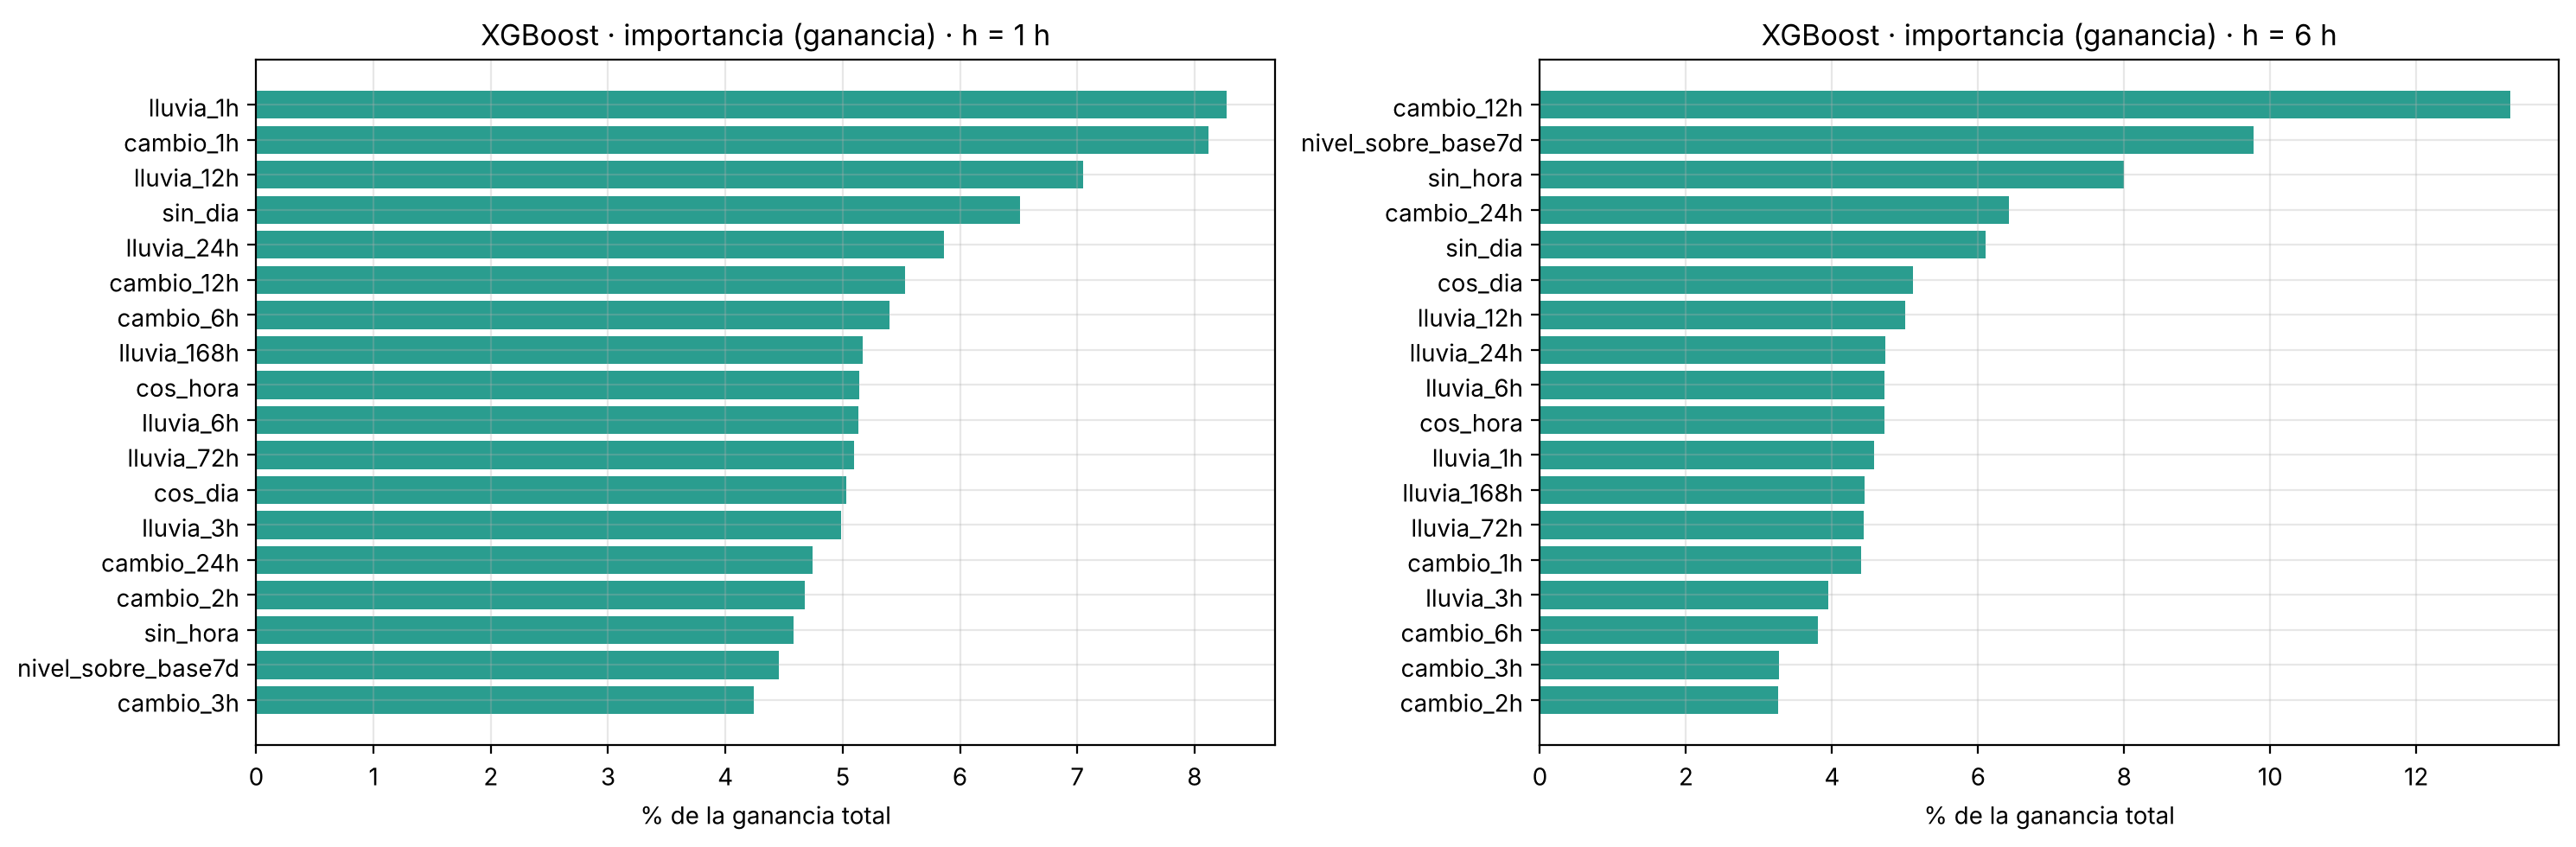

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, h in zip(axes, [1, H_PRINCIPAL]):
    imp = pd.Series(modelos_xgb[h].get_booster().get_score(importance_type="gain"))
    imp = (100 * imp / imp.sum()).reindex(atributos.columns).fillna(0).sort_values()
    ax.barh(imp.index, imp.values, color=COLORES["XGBoost"])
    ax.set_title(f"XGBoost · importancia (ganancia) · h = {h} h")
    ax.set_xlabel("% de la ganancia total")
plt.tight_layout()
plt.show()

**Lectura:** A 1 hora pesan la **lluvia de la última hora** y el **cambio de la última hora**: lo que está pasando ahora mismo. A 6 horas cobran importancia el **cambio de las últimas 12 h** (si el río viene subiendo o bajando), el **nivel sobre la base de 7 días** (un río crecido tiende a bajar) y la **hora del día** y la época del año. La lluvia acumulada de 1 a 7 días aparece repartida entre varias variables: aporta, pero ninguna sola domina. Esto coincide con el notebook 04. XGBoost baja el RMSE entre 6 % y 14 % respecto a la persistencia según el horizonte, y también mejora en nivel alto.

## 6. Modelo 3: LSTM

### ¿Qué es?

Una **LSTM** (*Long Short-Term Memory*) es una red neuronal que lee una secuencia paso a paso y lleva una "memoria" interna que decide qué recordar y qué olvidar. Es el modelo de *deep learning* más usado en predicción hidrológica porque aprende por sí sola los retrasos entre la lluvia y la respuesta del río, sin que haya que construir atributos a mano.

### Cómo se arma aquí

- **Entrada:** las últimas **72 horas** (3 días) antes de *t*. En cada hora la red ve: el nivel relativo al nivel actual, el nivel sobre la base de 7 días, la lluvia de la hora, la lluvia acumulada de 24 h y de 168 h, y la hora del día y el día del año (seno y coseno).
- **Salida:** los **cambios** de nivel de las siguientes 1 a 12 horas, todos a la vez (un solo modelo para todos los horizontes).
- **Arquitectura:** una capa LSTM de 64 unidades seguida de dos capas densas. Es una red pequeña a propósito: con 6 años de datos horarios, una red grande tiende a memorizar.
- **Escalado:** todas las entradas se llevan a media 0 y desviación 1 con las estadísticas del entrenamiento (las redes aprenden mal si las variables están en escalas muy distintas).
- **Entrenamiento:** optimizador Adam, lotes de 512 ventanas, error cuadrático medio. Después de cada pasada completa por los datos (*época*) se mide el error en **validación**; si no mejora en 5 épocas seguidas se detiene y se recupera la mejor versión (**parada temprana**).
- Solo se usan ventanas **sin horas vacías** de nivel o lluvia.

Se usa **PyTorch**. El resultado puede variar un poco entre computadores aunque se fije la semilla.

Ventanas de entrenamiento: 49,807 · de validación: 8,160


Entrenamiento detenido en la época 12; mejor época: 7 · tiempo: 60 s


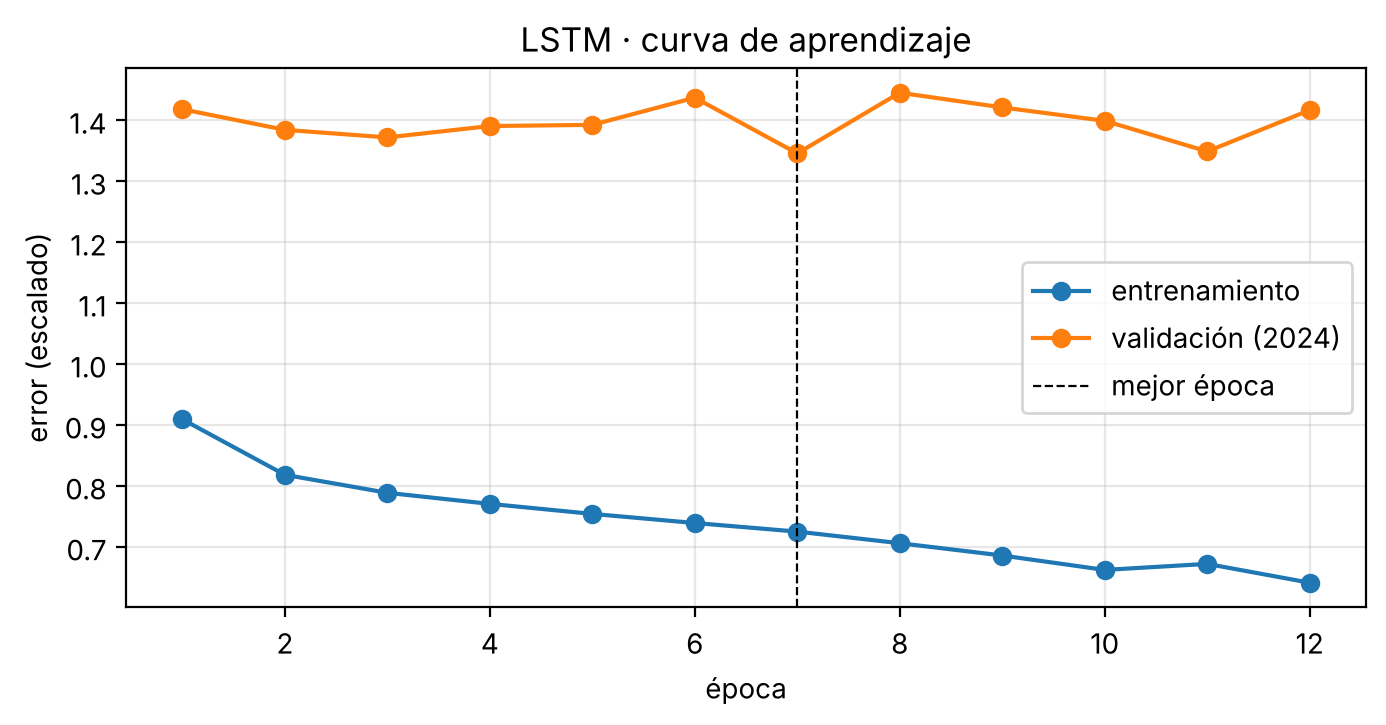

RMSE_cm                     NSE                    \
h                 1     3     6     12    1     3     6     12   
modelo                                                           
LSTM           2.840 5.030 6.420 7.350 0.910 0.710 0.530 0.390   
Persistencia   2.930 5.230 6.890 8.350 0.900 0.690 0.460 0.210   

             mejora_vs_persistencia_%                     
h                                  1     3     6      12  
modelo                                                    
LSTM                            3.060 3.860 6.790 11.950  
Persistencia                    0.000 0.000 0.000  0.000

In [8]:
import torch
import torch.nn as nn

torch.manual_seed(SEMILLA)
rng = np.random.default_rng(SEMILLA)

entradas = pd.DataFrame({
    "nivel_sobre_base7d": nivel - base_7d,
    "lluvia_1h": lluvia,
    "lluvia_24h": lluvia_acum["lluvia_24h"],
    "lluvia_168h": lluvia_acum["lluvia_168h"],
    "sin_hora": np.sin(2 * np.pi * df.index.hour / 24), "cos_hora": np.cos(2 * np.pi * df.index.hour / 24),
    "sin_dia": np.sin(2 * np.pi * df.index.dayofyear / 365.25), "cos_dia": np.cos(2 * np.pi * df.index.dayofyear / 365.25),
})
es_ent = (periodo == "entrenamiento").values
media, desv = entradas[es_ent].mean(), entradas[es_ent].std()
E = ((entradas - media) / desv).values.astype(np.float32)
nv = nivel.values

# Objetivo: cambio de nivel en t+1 ... t+12, dividido por su desviación para que todos pesen parecido
Y = np.column_stack([nivel.shift(-k).values - nv for k in range(1, H_MAX + 1)])
escala_y = np.nanstd(Y[es_ent], axis=0).astype(np.float32)
Yn = (Y / escala_y).astype(np.float32)

entradas_ok = pd.Series(~np.isnan(E).any(axis=1)).rolling(VENTANA, min_periods=VENTANA).sum().eq(VENTANA).values
valida = entradas_ok & ventana_ok.values

def ventanas(pos):
    # devuelve (n, 72, 9): las 8 entradas + nivel relativo al nivel actual
    idx = pos[:, None] + np.arange(-VENTANA + 1, 1)[None, :]
    relativo = (nv[idx] - nv[pos][:, None]) / (5 * escala_y[0])
    return torch.from_numpy(np.concatenate([E[idx], relativo[:, :, None].astype(np.float32)], axis=2))

tiene_objetivo = ~np.isnan(Y).all(axis=1)
pos_ent = np.where(valida & es_ent & tiene_objetivo)[0]
pos_val = np.where(valida & (periodo == "validación").values & tiene_objetivo)[0]
print(f"Ventanas de entrenamiento: {len(pos_ent):,} · de validación: {len(pos_val):,}")

class RedLSTM(nn.Module):
    def __init__(self, n_entradas, n_salidas, unidades=64):
        super().__init__()
        self.lstm = nn.LSTM(n_entradas, unidades, batch_first=True)
        self.cabeza = nn.Sequential(nn.Linear(unidades, 64), nn.ReLU(), nn.Linear(64, n_salidas))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.cabeza(salida[:, -1, :])  # se usa la memoria al final de la ventana

def error(pred_n, obj_n):
    hay = ~torch.isnan(obj_n)                 # algunas horas futuras pueden estar vacías
    return ((pred_n - torch.nan_to_num(obj_n)) ** 2)[hay].mean()

red = RedLSTM(E.shape[1] + 1, H_MAX)
optimizador = torch.optim.Adam(red.parameters(), lr=1e-3)
X_val, Y_val = ventanas(pos_val), torch.from_numpy(Yn[pos_val])
historial, mejor_error, sin_mejora, inicio = [], np.inf, 0, time.time()
for epoca in range(1, 41):
    red.train()
    orden, acumulado = rng.permutation(pos_ent), 0.0
    for i in range(0, len(orden), 512):
        lote = orden[i:i + 512]
        optimizador.zero_grad()
        perdida = error(red(ventanas(lote)), torch.from_numpy(Yn[lote]))
        perdida.backward()
        optimizador.step()
        acumulado += perdida.item() * len(lote)
    red.eval()
    with torch.no_grad():
        error_val = error(red(X_val), Y_val).item()
    historial.append((acumulado / len(orden), error_val))
    if error_val < mejor_error:
        mejor_error, sin_mejora, mejor_estado = error_val, 0, {k: v.clone() for k, v in red.state_dict().items()}
    else:
        sin_mejora += 1
        if sin_mejora >= 5:
            break
red.load_state_dict(mejor_estado)
red.eval()
mejor_epoca = int(np.argmin([v for _, v in historial])) + 1
print(f"Entrenamiento detenido en la época {epoca}; mejor época: {mejor_epoca} · tiempo: {time.time() - inicio:.0f} s")

pos_todas = np.where(valida)[0]
cambios = np.full((len(df), H_MAX), np.nan)
with torch.no_grad():
    for i in range(0, len(pos_todas), 4096):
        lote = pos_todas[i:i + 4096]
        cambios[lote] = red(ventanas(lote)).numpy() * escala_y
pred["LSTM"] = pd.DataFrame({h: nv + cambios[:, h - 1] for h in HORIZONTES}, index=df.index)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(1, len(historial) + 1), [a for a, _ in historial], marker="o", label="entrenamiento")
ax.plot(range(1, len(historial) + 1), [v for _, v in historial], marker="o", label="validación (2024)")
ax.axvline(mejor_epoca, color="black", ls="--", lw=0.8, label="mejor época")
ax.set_xlabel("época")
ax.set_ylabel("error (escalado)")
ax.set_title("LSTM · curva de aprendizaje")
ax.legend()
plt.show()
display(resumen_modelo("LSTM"))

**Cómo leer la curva de aprendizaje:** el error de entrenamiento siempre baja, porque la red se ajusta cada vez más a esos datos. Lo que importa es el de **validación**: cuando deja de bajar o empieza a subir, la red está empezando a memorizar el entrenamiento en lugar de aprender patrones generales, y ahí se detiene.

**Lectura:** La red deja de mejorar en validación después de unas 7 épocas: con una sola estación y pocas crecidas grandes por año, no hay tantos ejemplos de lo que más interesa. Aun así, la LSTM le gana a la persistencia en todos los horizontes (7 % a 6 h) y queda **muy cerca de XGBoost, apenas por detrás**.

## 7. Modelo 4: Prophet

### ¿Qué es?

**Prophet** (de Meta) descompone la serie en: una **tendencia** lenta que puede cambiar de pendiente en algunos puntos, un **ciclo anual** (temporadas de lluvia), un **ciclo diario** y el efecto de **variables externas**. Es muy fácil de usar y bueno para series con estacionalidad marcada y para horizontes largos (semanas o meses).

Su gran limitación para este problema: **no usa el nivel de las horas anteriores**. Predice el nivel solo a partir de la fecha, la hora y la lluvia. Por eso no se entera de que el río "viene subiendo" y, además, predice el **nivel absoluto**, así que lo afectan de lleno los cambios del nivel de base.

### Cómo se arma aquí

- Variables externas: la lluvia acumulada de 24, 72 y 168 horas **hasta la hora *t*** (es decir, retrasada *h* horas respecto a la hora que se predice, para no usar lluvia futura). Por eso se entrena un modelo por horizonte.
- Ciclos anual y diario activados; el semanal no (el río no sabe qué día de la semana es).
- Se entrena con 2018-2023 (Prophet ignora solo las horas vacías).

In [9]:
from prophet import Prophet

pred_prophet, inicio = {}, time.time()
for h in HORIZONTES:
    datos = pd.DataFrame({"ds": df.index, "y": nivel.values})
    for w in [24, 72, 168]:
        datos[f"lluvia_{w}h"] = lluvia_acum[f"lluvia_{w}h"].shift(h).values  # lluvia conocida hasta t = (t+h) - h
    datos = datos.dropna(subset=[f"lluvia_{w}h" for w in [24, 72, 168]])
    ent = datos[(datos.ds >= "2018-01-01") & (datos.ds <= FIN_TRAIN)].dropna(subset=["y"])
    modelo = Prophet(yearly_seasonality=True, daily_seasonality=True, weekly_seasonality=False)
    for w in [24, 72, 168]:
        modelo.add_regressor(f"lluvia_{w}h")
    modelo.fit(ent)
    salida = modelo.predict(datos.drop(columns="y"))
    # la predicción es para la hora t+h; se reindexa por la hora de origen t
    pred_prophet[h] = pd.Series(salida.yhat.values, index=datos.ds.values).reindex(df.index).shift(-h)
    if h == H_PRINCIPAL:
        prophet_principal, salida_principal = modelo, salida
    print(f"h = {h:>2} h listo ({time.time() - inicio:.0f} s)")
pred["Prophet"] = pd.DataFrame(pred_prophet, index=df.index)
display(resumen_modelo("Prophet"))

Importing plotly failed. Interactive plots will not work.


17:33:29 - cmdstanpy - INFO - Chain [1] start processing


17:34:01 - cmdstanpy - INFO - Chain [1] done processing


h =  1 h listo (42 s)


17:34:10 - cmdstanpy - INFO - Chain [1] start processing


17:34:46 - cmdstanpy - INFO - Chain [1] done processing


... (4 outputs left out)

17:35:34 - cmdstanpy - INFO - Chain [1] start processing


17:36:16 - cmdstanpy - INFO - Chain [1] done processing


h = 12 h listo (176 s)


RMSE_cm                          NSE                          \
h                 1      3      6      12      1       3       6       12   
modelo                                                                      
Persistencia   2.930  5.230  6.890  8.350   0.900   0.690   0.460   0.210   
Prophet       46.850 47.030 46.450 45.680 -23.900 -24.070 -23.440 -22.670   

             mejora_vs_persistencia_%                             
h                                  1        3        6        12  
modelo                                                            
Persistencia                    0.000    0.000    0.000    0.000  
Prophet                    -1,499.330 -799.010 -574.320 -447.080

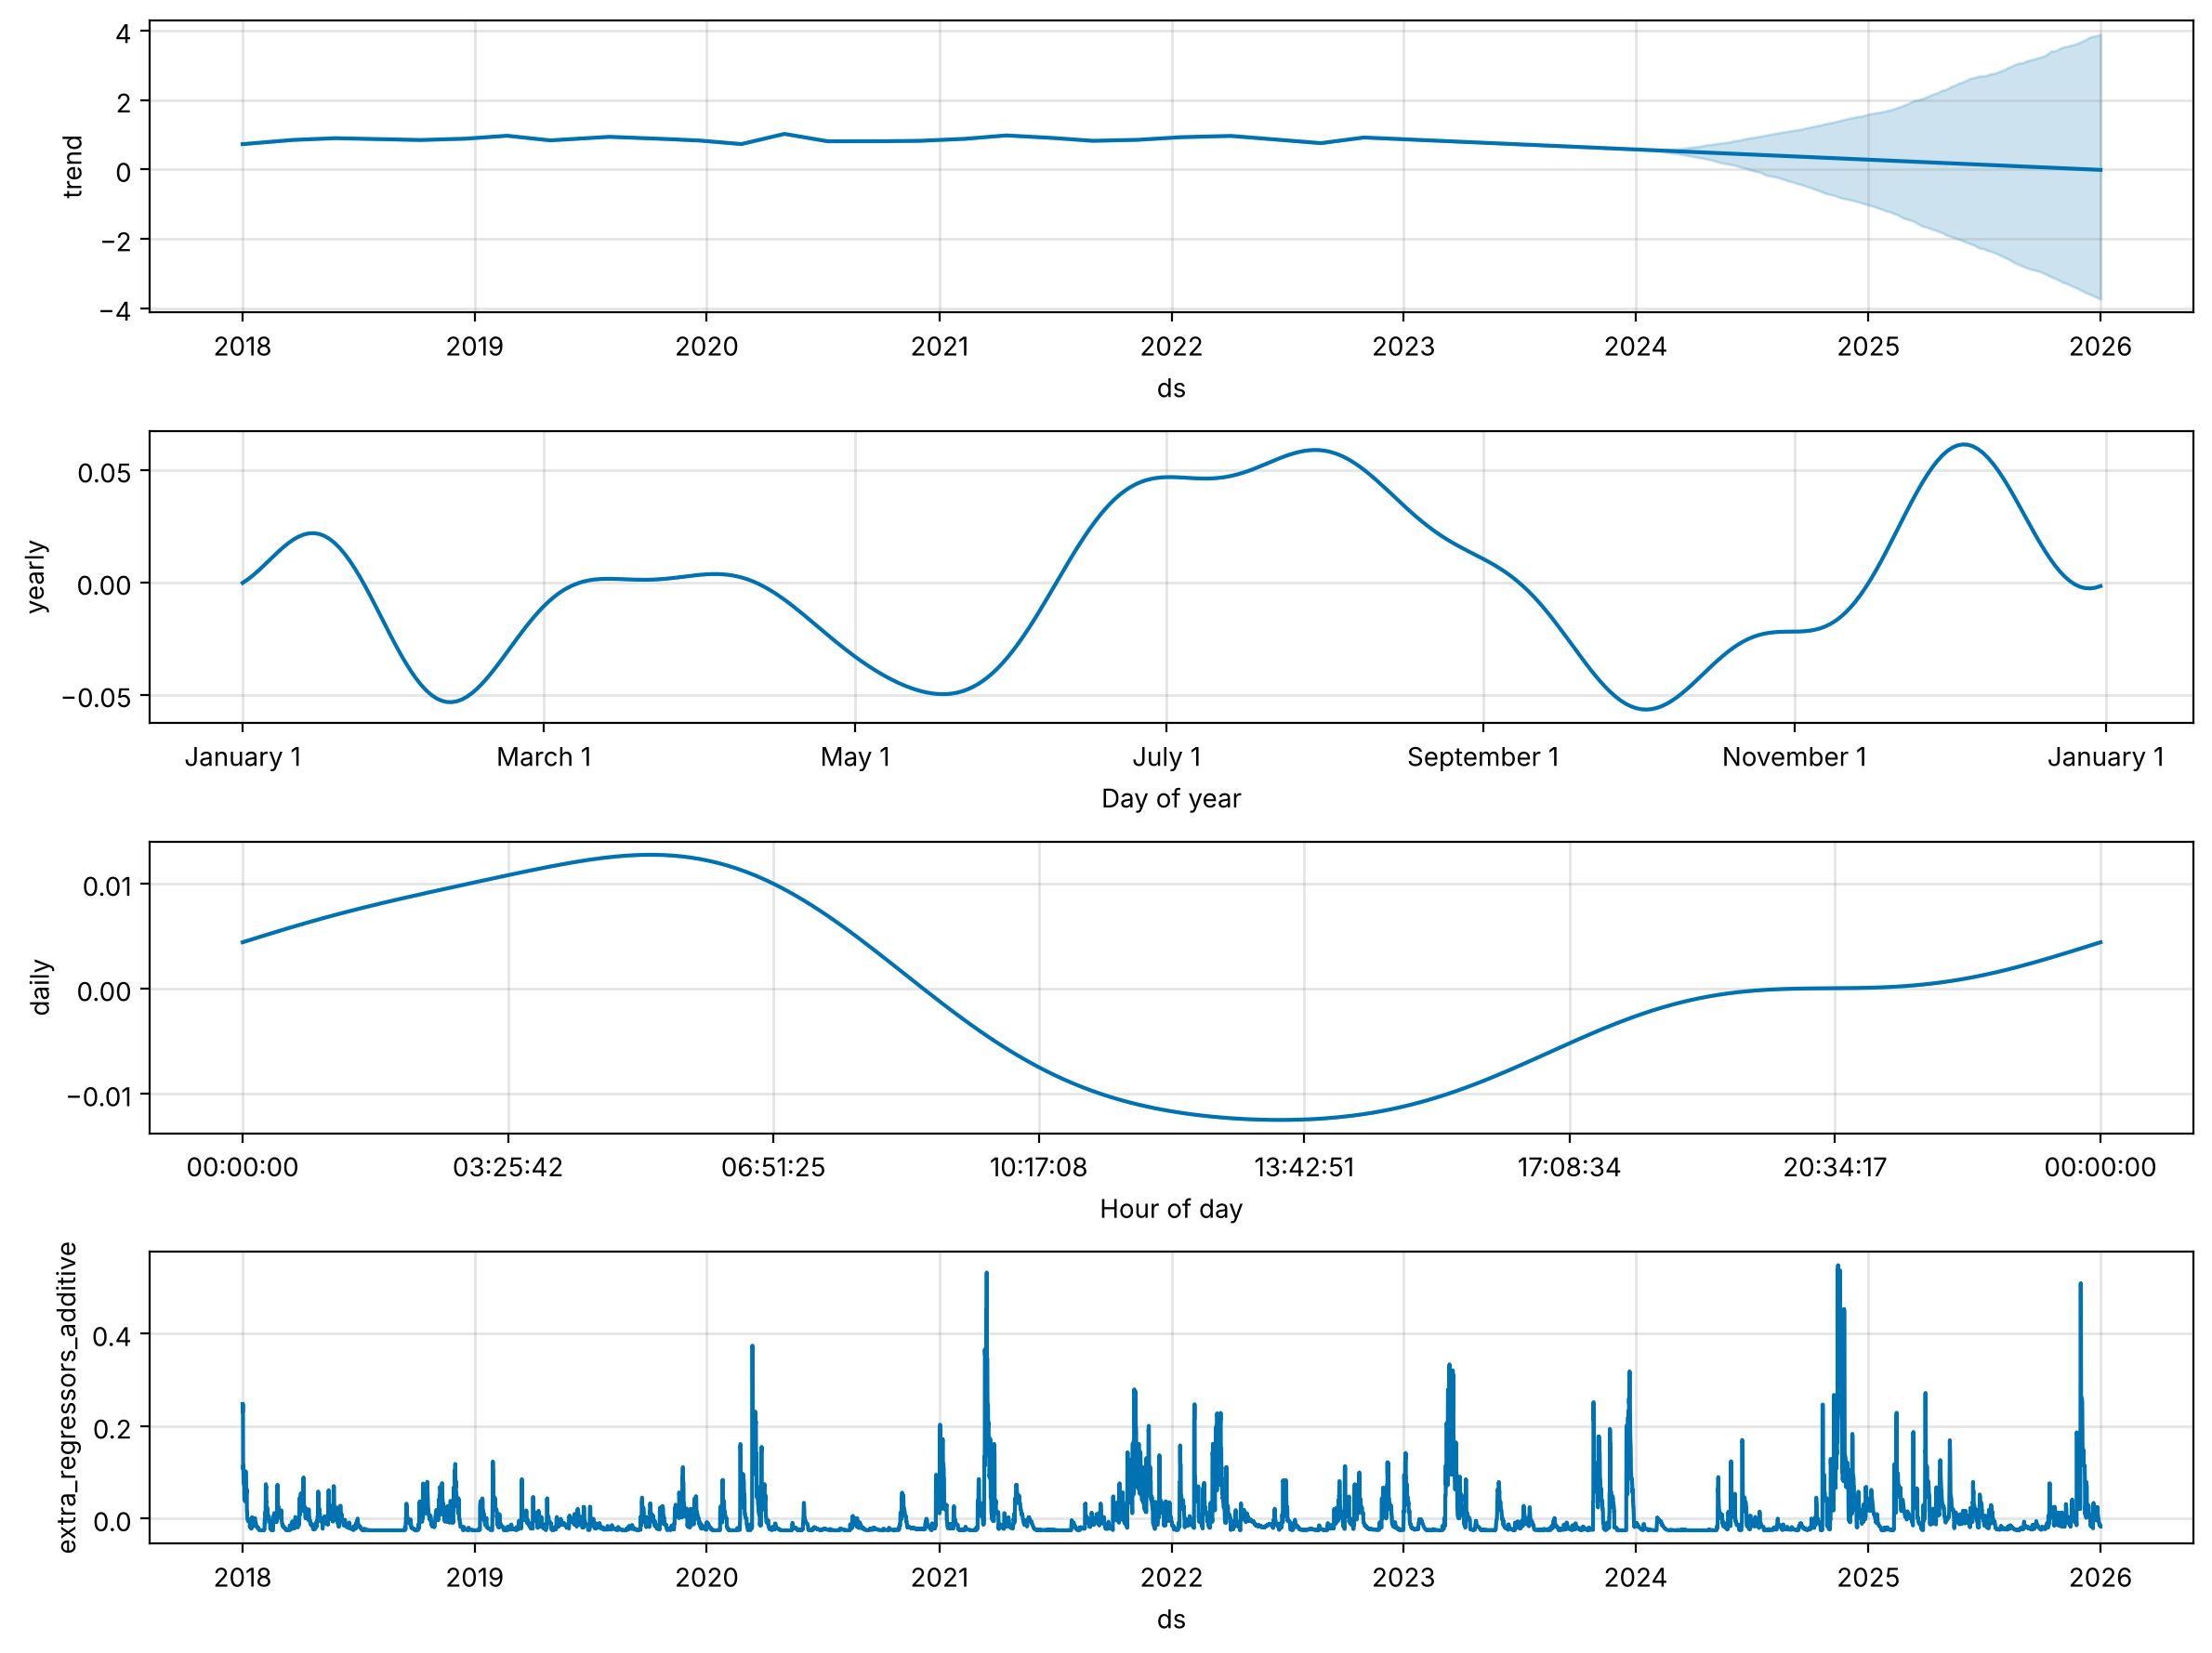

In [10]:
fig = prophet_principal.plot_components(salida_principal[salida_principal.ds >= "2018-01-01"], figsize=(12, 9))
plt.show()

**Cómo leer los componentes:** `trend` es la tendencia lenta (fíjese en cómo la extiende hacia 2024-2025); `yearly` es el ciclo anual; `daily` el ciclo diario; `extra_regressors_additive` es el efecto de la lluvia acumulada.

**Lectura:** Prophet **falla por completo** en La Lindosa (error de unos 45 cm, frente a ~7 cm de la persistencia). Se ve en el componente `trend`: aprendió que el nivel venía bajando en 2023 y **extrapoló esa bajada** hacia 2024-2025, hasta predecir niveles cercanos a 0,1-0,2 m cuando el río real estaba alrededor de 0,6 m. Es justo el problema del nivel de base: Prophet no puede "mirar" el nivel actual para corregirse. Sus ciclos anual y diario sí son razonables (más nivel en junio-agosto y noviembre-diciembre; un ciclo diario de ±1 cm), pero no sirven para predecir a pocas horas.

## 8. Comparación final

### 8.1 Tabla de errores en 2025

Todas las métricas en las mismas horas de prueba. Arriba, todas las horas; abajo, solo horas de **nivel alto** (por encima del percentil 95 de 2025).

In [11]:
MODELOS = ["SARIMAX", "XGBoost", "LSTM", "Prophet"]
metricas = tabla_metricas(["Persistencia"] + MODELOS)
salida_csv = RAIZ / "models" / ESTACION / "metricas_prueba_2025.csv"
salida_csv.parent.mkdir(parents=True, exist_ok=True)
metricas.round(4).to_csv(salida_csv, index=False)

for sub in ["todas", "nivel alto"]:
    t = metricas[metricas.subconjunto == sub]
    print(f"\n{NOMBRE} · horas: {sub}")
    display(t.pivot(index="modelo", columns="h", values=["RMSE_cm", "MAE_cm", "NSE", "mejora_vs_persistencia_%"])
             .loc[["Persistencia"] + MODELOS].round(2))
print(f"Tabla guardada en {salida_csv.relative_to(RAIZ)}")


La Lindosa · horas: todas


RMSE_cm                      MAE_cm                          NSE  \
h                 1      3      6      12     1      3      6      12      1    
modelo                                                                          
Persistencia   2.930  5.230  6.890  8.350  1.290  2.750  4.170  5.470   0.900   
SARIMAX        2.910  5.240  6.890  8.300  1.270  2.710  4.030  5.150   0.900   
XGBoost        2.730  4.900  6.340  7.190  1.230  2.560  3.800  4.530   0.920   
LSTM           2.840  5.030  6.420  7.350  1.310  2.680  3.870  4.770   0.910   
Prophet       46.850 47.030 46.450 45.680 45.510 45.690 45.090 44.280 -23.900   

                                     mejora_vs_persistencia_%           \
h                 3       6       12                       1        3    
modelo                                                                   
Persistencia   0.690   0.460   0.210                    0.000    0.000   
SARIMAX        0.690   0.460   0.220                    0.650   -0.160   
XGBoost        0.730   0.540   0.410                    6.770    6.310   
LSTM           0.710   0.530   0.390                    3.060    3.860   
Prophet      -24.070 -23.440 -22.670               -1,499.330 -799.010   

                                
h                  6        12  
modelo                          
Persistencia    0.000    0.000  
SARIMAX        -0.010    0.620  
XGBoost         7.970   13.930  
LSTM            6.790   11.950  
Prophet      -574.320 -447.080


La Lindosa · horas: nivel alto


RMSE_cm                      MAE_cm                          NSE  \
h                 1      3      6      12     1      3      6      12      1    
modelo                                                                          
Persistencia   9.150 14.850 18.110 21.160  4.620  9.180 12.720 15.810   0.050   
SARIMAX        9.150 15.120 18.760 21.720  4.530  9.300 13.130 16.250   0.050   
XGBoost        8.170 13.900 16.450 19.970  4.080  8.300 11.240 14.680   0.240   
LSTM           8.470 13.840 16.810 19.350  4.270  8.310 11.380 14.280   0.190   
Prophet       65.980 66.640 66.460 66.210 65.150 65.880 65.700 65.440 -48.260   

                                     mejora_vs_persistencia_%           \
h                 3       6       12                       1        3    
modelo                                                                   
Persistencia  -1.490  -2.710  -4.100                    0.000    0.000   
SARIMAX       -1.590  -2.980  -4.370                    0.030   -1.870   
XGBoost       -1.190  -2.060  -3.540                   10.720    6.380   
LSTM          -1.170  -2.200  -3.260                    7.510    6.750   
Prophet      -49.240 -48.970 -48.880                 -620.830 -348.880   

                                
h                  6        12  
modelo                          
Persistencia    0.000    0.000  
SARIMAX        -3.620   -2.650  
XGBoost         9.140    5.620  
LSTM            7.170    8.570  
Prophet      -267.020 -212.820

Tabla guardada en models/La_Lindosa/metricas_prueba_2025.csv


### 8.2 Error según el horizonte

A la izquierda, el RMSE de cada modelo para cada horizonte (más abajo es mejor). A la derecha, cuánto mejora cada modelo sobre la persistencia (más arriba es mejor; por debajo de 0 es peor que no hacer nada). Prophet queda fuera de escala en la izquierda, así que su valor se escribe en el título.

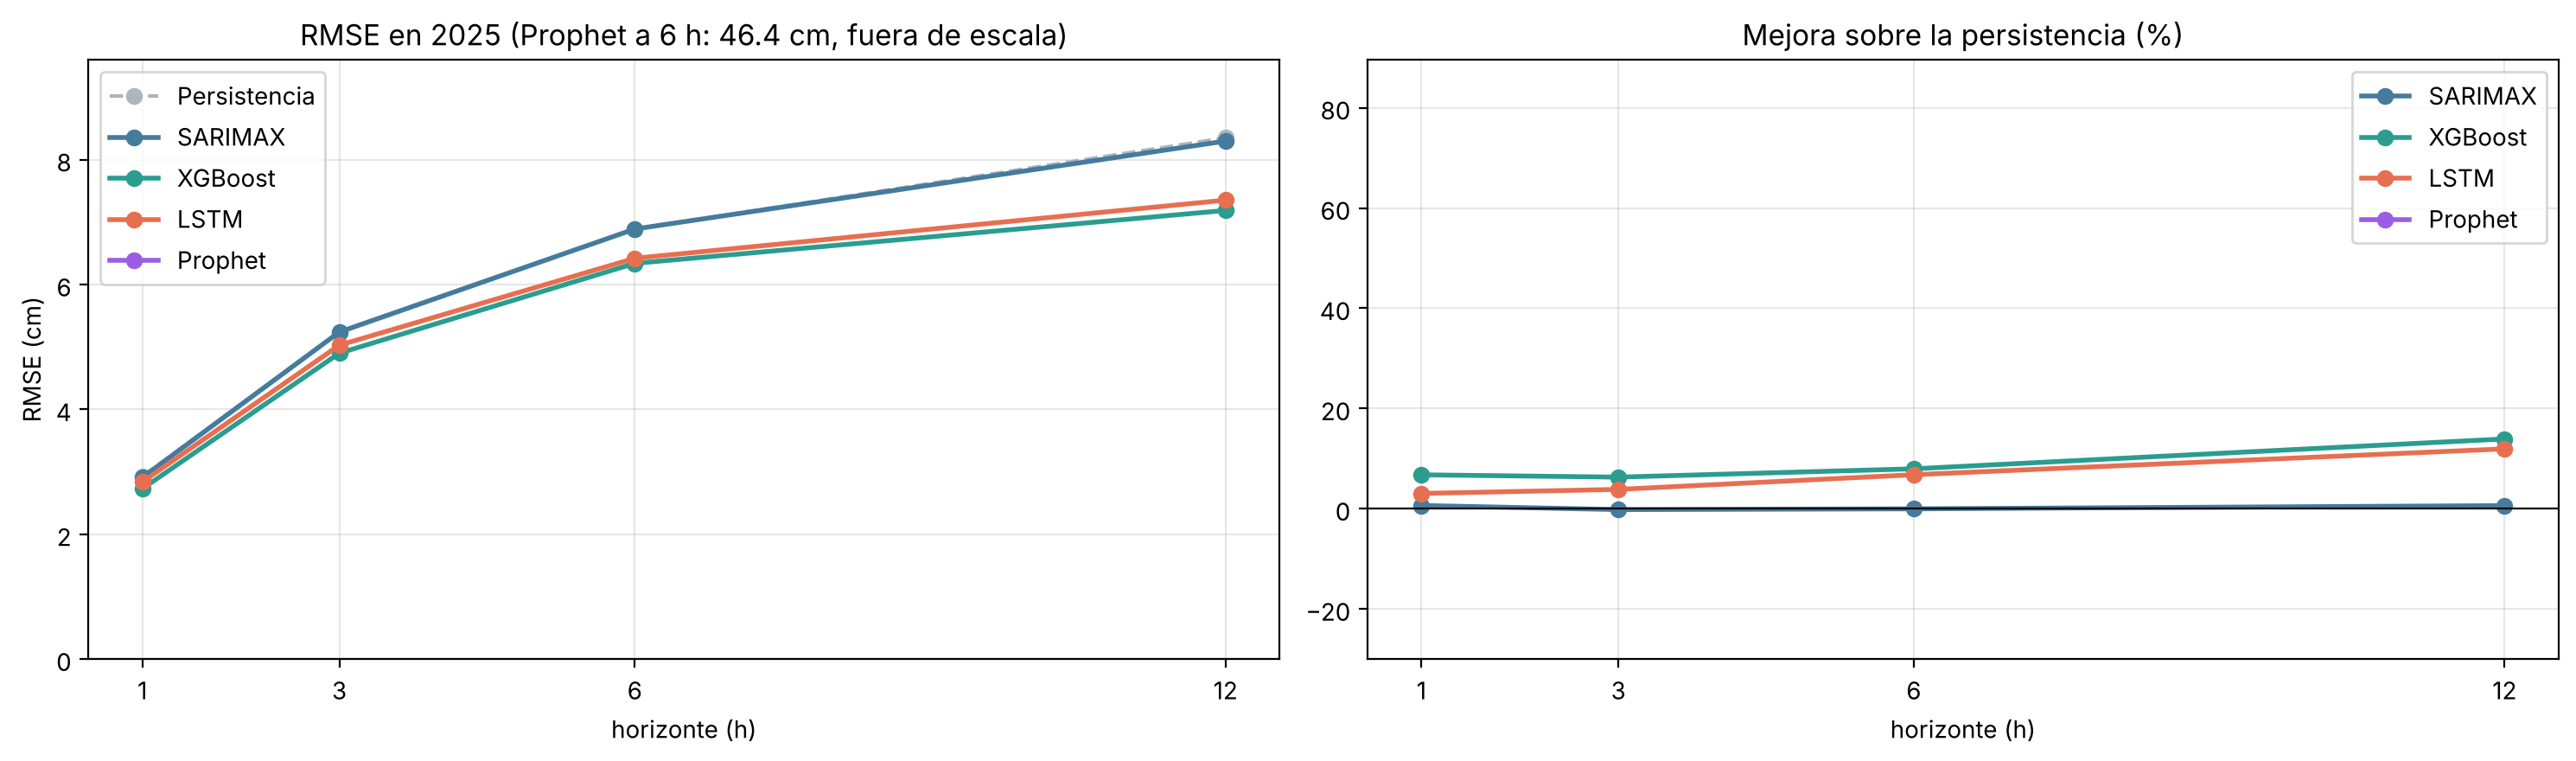

In [12]:
todas = metricas[metricas.subconjunto == "todas"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for nombre in ["Persistencia"] + MODELOS:
    t = todas[todas.modelo == nombre]
    axes[0].plot(t.h, t.RMSE_cm, marker="o", color=COLORES[nombre], label=nombre, lw=2 if nombre != "Persistencia" else 1.5,
                 ls="--" if nombre == "Persistencia" else "-")
    if nombre != "Persistencia":
        axes[1].plot(t.h, t["mejora_vs_persistencia_%"], marker="o", color=COLORES[nombre], label=nombre, lw=2)
techo = todas[todas.modelo != "Prophet"].RMSE_cm.max() * 1.15
prophet_rmse = todas[(todas.modelo == "Prophet") & (todas.h == H_PRINCIPAL)].RMSE_cm.iloc[0]
axes[0].set_ylim(0, techo)
axes[0].set_title(f"RMSE en 2025 (Prophet a {H_PRINCIPAL} h: {prophet_rmse:.1f} cm, fuera de escala)")
axes[0].set_ylabel("RMSE (cm)")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylim(max(-30, todas[todas.modelo != "Persistencia"]["mejora_vs_persistencia_%"].min() - 5), None)
axes[1].set_title("Mejora sobre la persistencia (%)")
for ax in axes:
    ax.set_xticks(HORIZONTES)
    ax.set_xlabel("horizonte (h)")
    ax.legend()
plt.tight_layout()
plt.show()

### 8.3 La mayor crecida de 2025, vista por cada modelo

Se toma el pico más alto de 2025 (entre las horas que entran en la evaluación, para que todos los modelos tengan predicción) y se muestra lo que cada modelo predijo **con 6 horas de anticipación** para cada hora del evento (cada punto de una curva es una predicción hecha 6 horas antes). Así se ve si el modelo anticipa la subida, si llega a la altura del pico y si se retrasa.

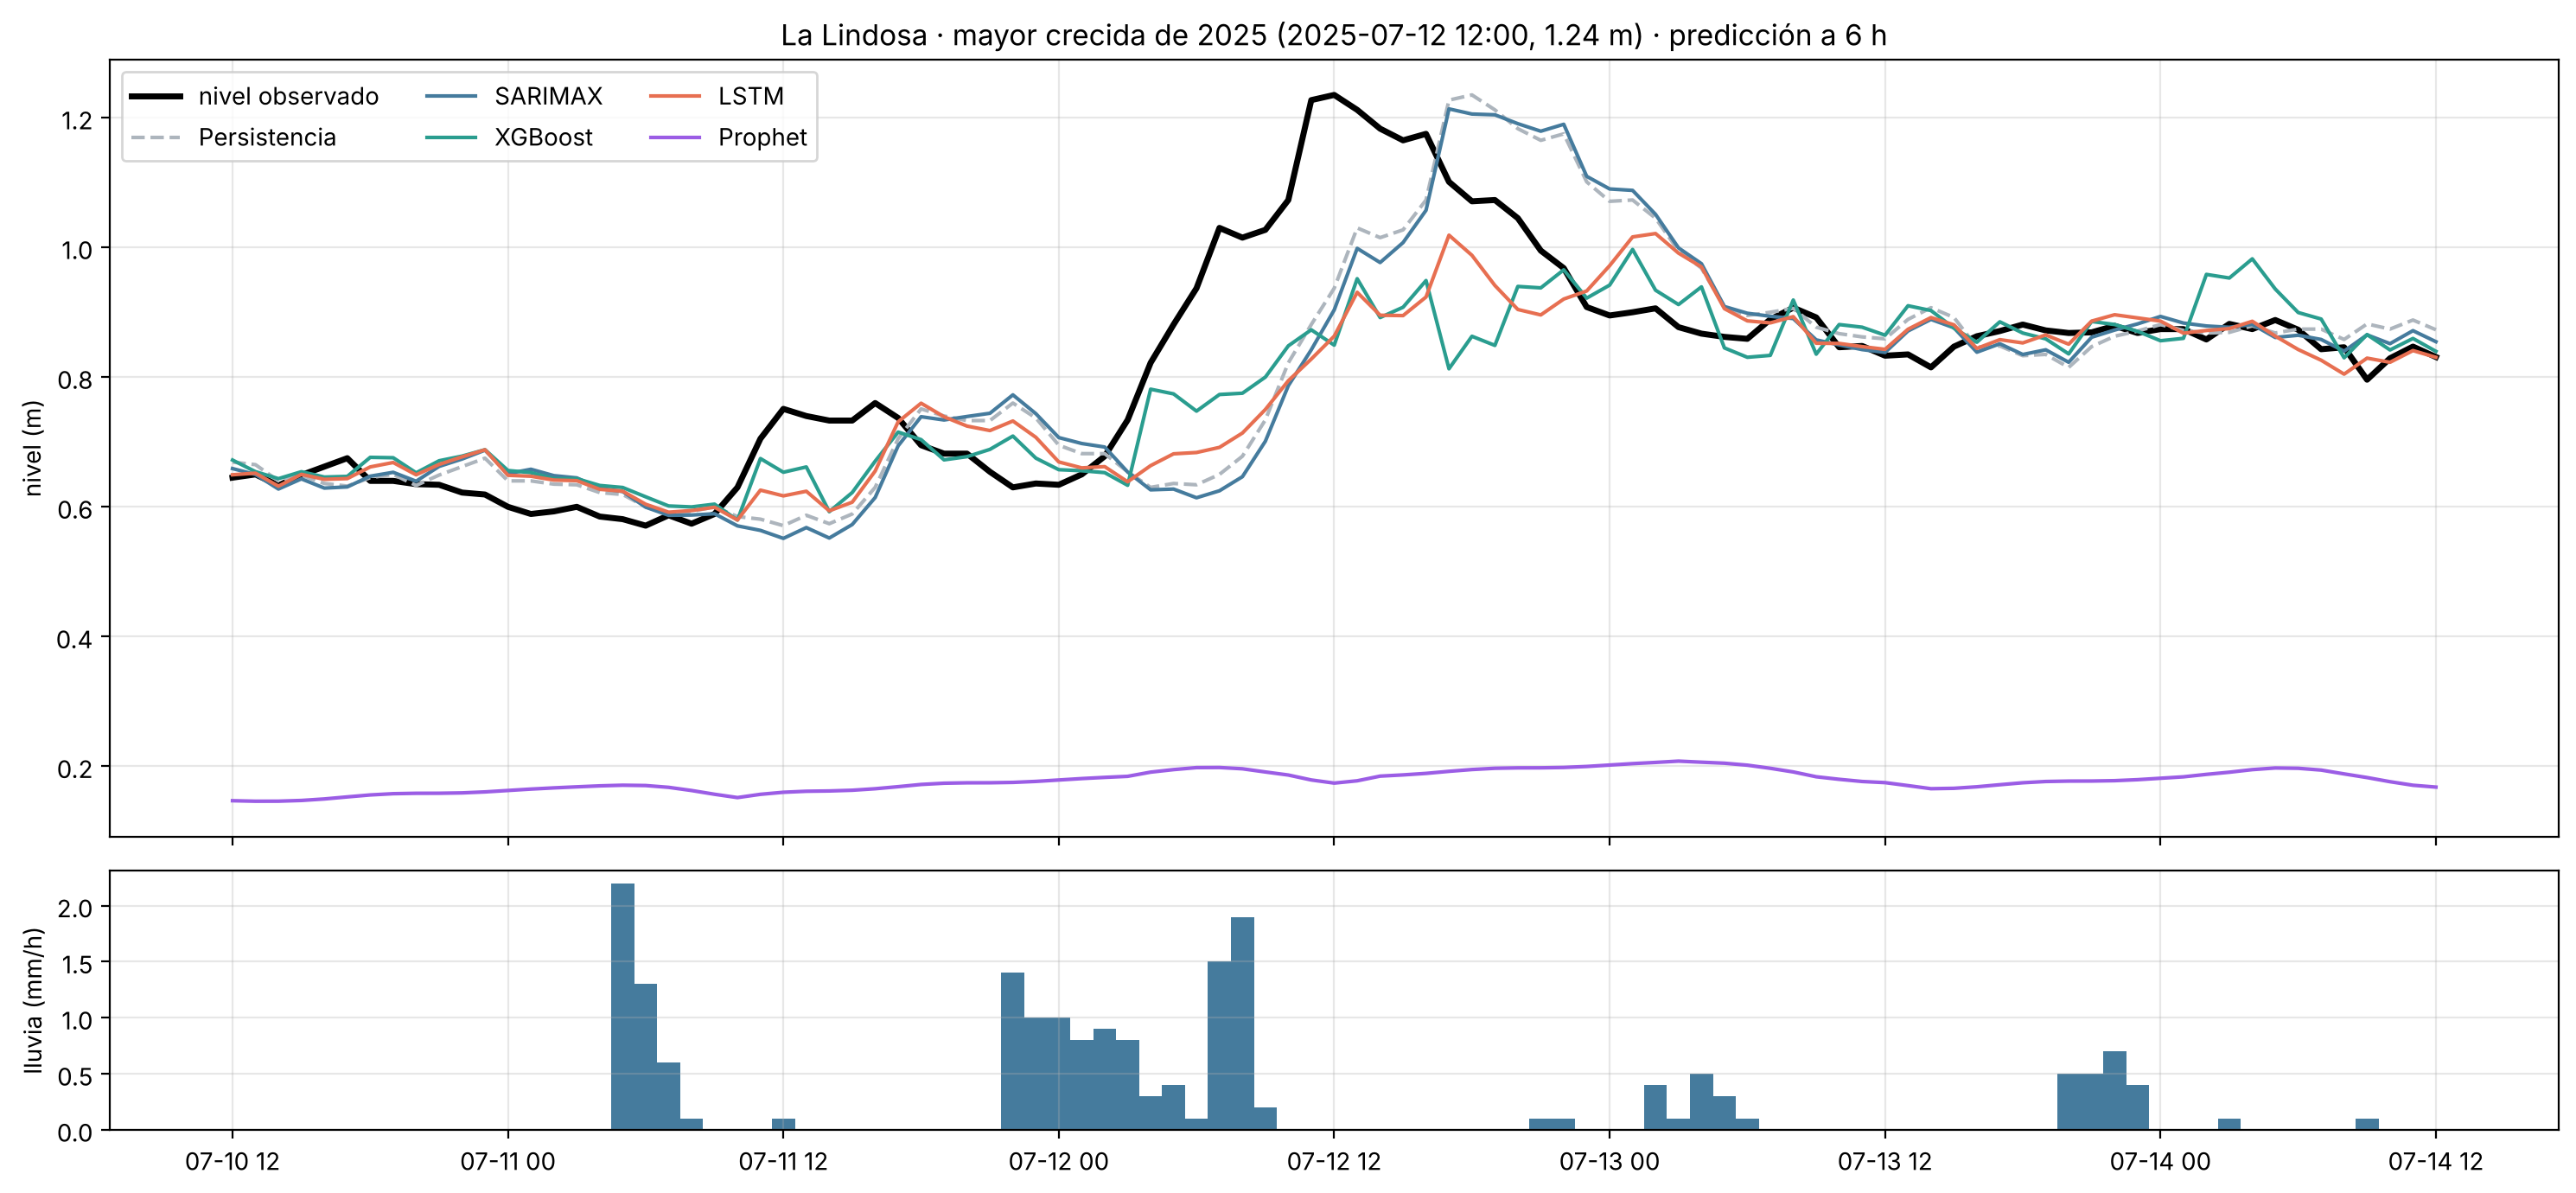

In [13]:
h = H_PRINCIPAL
# se busca el pico más alto de 2025 entre las horas que se pueden evaluar (origen t - h con datos completos)
evaluables = evaluar[h][evaluar[h]].index + pd.Timedelta(hours=h)
pico = nivel[evaluables].idxmax()
ventana_evento = slice(pico - pd.Timedelta(hours=48), pico + pd.Timedelta(hours=48))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(nivel[ventana_evento], color="black", lw=2.5, label="nivel observado")
for nombre in ["Persistencia"] + MODELOS:
    p = pred[nombre][h].shift(h)  # predicción hecha h horas antes, ubicada en la hora que predice
    ax1.plot(p[ventana_evento], color=COLORES[nombre], lw=1.5, ls="--" if nombre == "Persistencia" else "-", label=nombre)
ax1.set_ylabel("nivel (m)")
ax1.set_title(f"{NOMBRE} · mayor crecida de 2025 ({pico:%Y-%m-%d %H:%M}, {nivel[pico]:.2f} m) · predicción a {h} h")
ax1.legend(ncol=3, loc="upper left")
ax2.bar(lluvia[ventana_evento].index, lluvia[ventana_evento].values, width=1 / 24, color="#457b9d")
ax2.set_ylabel("lluvia (mm/h)")
plt.tight_layout()
plt.show()

**Lectura:** La crecida del 12 de julio de 2025 llegó a 1,24 m. Ningún modelo la anticipa completa con 6 horas: la subida empieza con la lluvia de la madrugada del 12 y, 6 horas antes, esa lluvia todavía no había caído. **SARIMAX y la persistencia** repiten el pico con 6 horas de retraso (cuando el río ya está bajando), que es lo peor para una alerta. **XGBoost y la LSTM** suben antes y más cerca de la curva real durante la subida (de 0,65 a ~0,8-0,9 m), pero se quedan cortos en el pico (~0,95-1,0 m) y lo "aplanan". **Prophet** está fuera de la gráfica útil, alrededor de 0,2 m.

### 8.4 Predicción contra observación

Cada punto es una hora de 2025 (horizonte de 6 h). Si el modelo fuera perfecto, todos los puntos caerían sobre la diagonal. Puntos por debajo de la diagonal en la parte alta = el modelo **subestima** las crecidas.

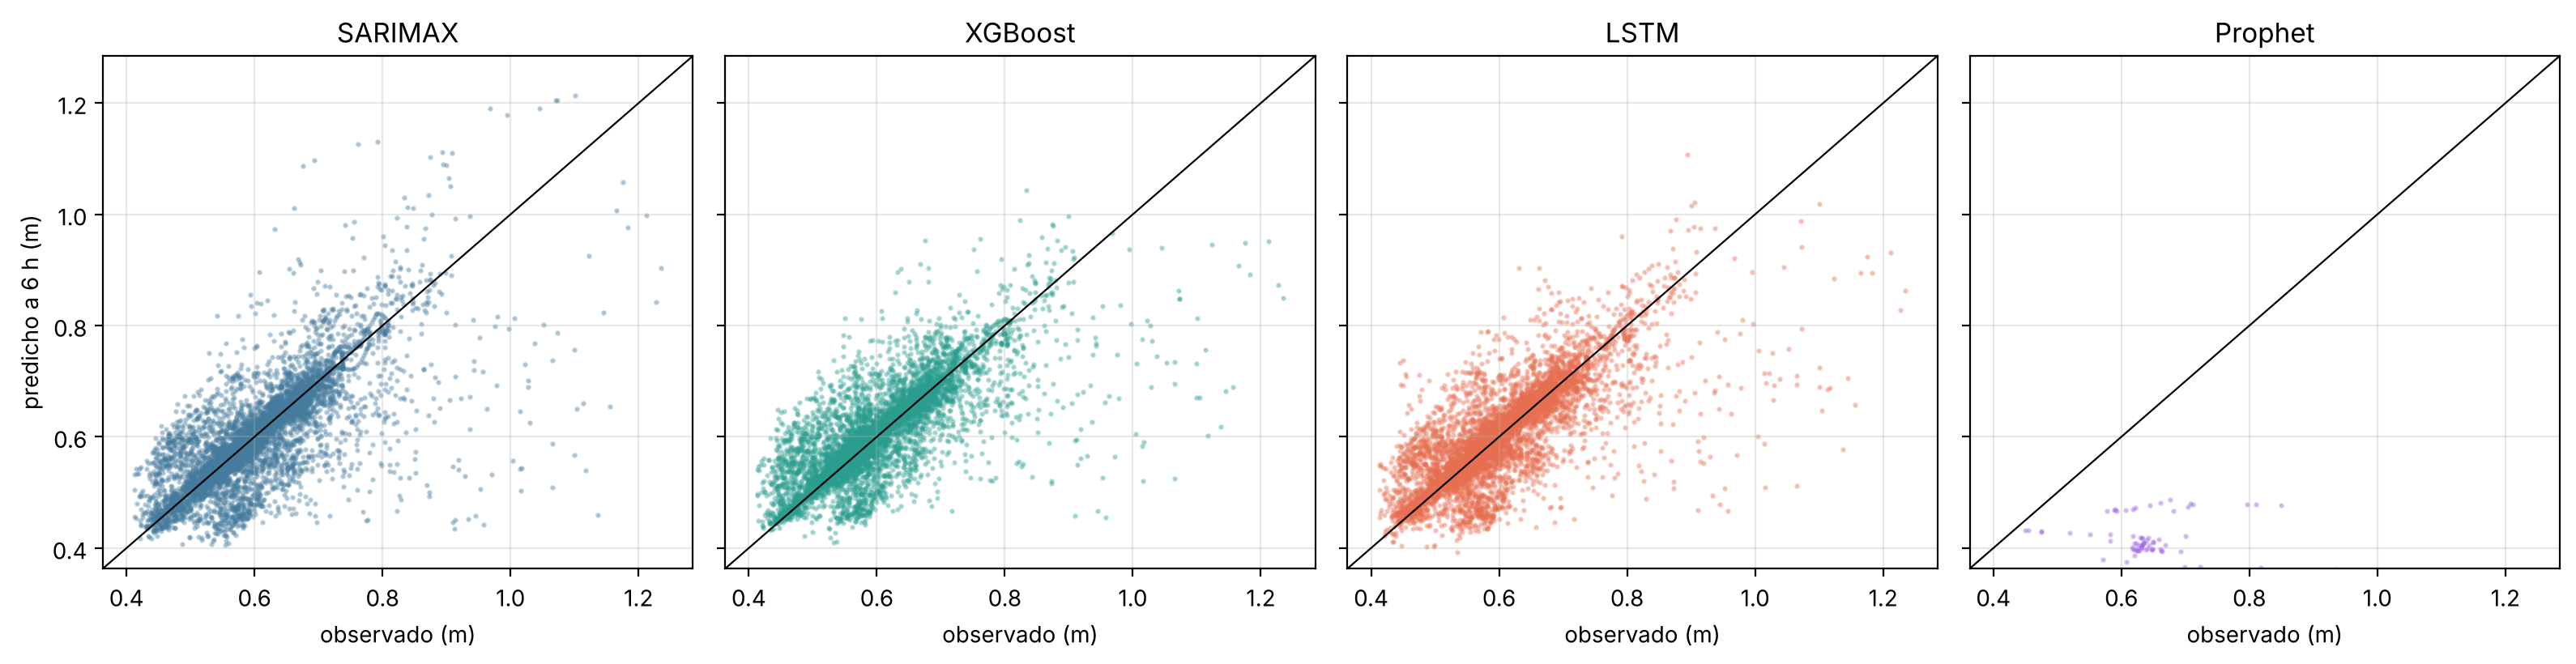

In [14]:
h = H_PRINCIPAL
m = evaluar[h]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharex=True, sharey=True)
lim = (real[h][m].min() - 0.05, real[h][m].max() + 0.05)
for ax, nombre in zip(axes, MODELOS):
    ax.scatter(real[h][m], pred[nombre][h][m], s=2, alpha=0.3, color=COLORES[nombre])
    ax.plot(lim, lim, color="black", lw=0.8)
    ax.set_title(nombre)
    ax.set_xlabel("observado (m)")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
axes[0].set_ylabel(f"predicho a {h} h (m)")
plt.tight_layout()
plt.show()

### 8.5 ¿Cuál es el mejor modelo para La Lindosa?

Criterio: el modelo con **menor RMSE a 6 horas** en todas las horas de 2025. Se revisa además que también sea bueno en **nivel alto** (crecidas) y que **le gane a la persistencia**; si un modelo gana en un criterio y otro en el otro, se dice explícitamente.

In [15]:
h = H_PRINCIPAL
t = metricas[(metricas.h == h) & (metricas.modelo.isin(MODELOS))]
general = t[t.subconjunto == "todas"].set_index("modelo")
alto = t[t.subconjunto == "nivel alto"].set_index("modelo")
ranking = pd.DataFrame({
    "RMSE (cm)": general.RMSE_cm, "NSE": general.NSE, "mejora vs persistencia (%)": general["mejora_vs_persistencia_%"],
    "RMSE nivel alto (cm)": alto.RMSE_cm, "mejora nivel alto (%)": alto["mejora_vs_persistencia_%"],
}).sort_values("RMSE (cm)")
ranking.insert(0, "puesto", range(1, len(ranking) + 1))
display(ranking.round(2))

mejor = ranking.index[0]
# En nivel alto solo se comparan modelos que le ganan a la persistencia en general: un modelo con un sesgo
# (por ejemplo, que siempre predice alto) puede "acertar" en las crecidas sin ser un buen modelo.
utiles = ranking[ranking["mejora vs persistencia (%)"] > 0]
mejor_alto = utiles["RMSE nivel alto (cm)"].idxmin()
print(f"MEJOR MODELO PARA {NOMBRE.upper()} (horizonte {h} h): {mejor}")
print(f"  · RMSE {ranking.loc[mejor, 'RMSE (cm)']:.2f} cm, NSE {ranking.loc[mejor, 'NSE']:.2f}, "
      f"{ranking.loc[mejor, 'mejora vs persistencia (%)']:.1f} % mejor que la persistencia")
if mejor_alto == mejor:
    print(f"  · También es el mejor en nivel alto (RMSE {ranking.loc[mejor, 'RMSE nivel alto (cm)']:.2f} cm).")
else:
    print(f"  · En nivel alto el mejor es {mejor_alto} (RMSE {ranking.loc[mejor_alto, 'RMSE nivel alto (cm)']:.2f} cm "
          f"frente a {ranking.loc[mejor, 'RMSE nivel alto (cm)']:.2f} cm de {mejor}).")
gana_todos = all(
    metricas[(metricas.h == hh) & (metricas.subconjunto == "todas")].set_index("modelo").RMSE_cm[MODELOS].idxmin() == mejor
    for hh in HORIZONTES)
print(f"  · ¿Es el mejor en todos los horizontes (1, 3, 6 y 12 h)? {'Sí' if gana_todos else 'No'}")

,puesto,RMSE (cm),NSE,mejora vs persistencia (%),RMSE nivel alto (cm),mejora nivel alto (%)
modelo,,,,,,
XGBoost,1,6.340,0.540,7.970,16.450,9.140
LSTM,2,6.420,0.530,6.790,16.810,7.170
SARIMAX,3,6.890,0.460,-0.010,18.760,-3.620
Prophet,4,46.450,-23.440,-574.320,66.460,-267.020


MEJOR MODELO PARA LA LINDOSA (horizonte 6 h): XGBoost
  · RMSE 6.34 cm, NSE 0.54, 8.0 % mejor que la persistencia
  · También es el mejor en nivel alto (RMSE 16.45 cm).
  · ¿Es el mejor en todos los horizontes (1, 3, 6 y 12 h)? Sí


## 9. Conclusiones

**Modelo recomendado para La Lindosa: XGBoost.**

| Modelo | RMSE a 6 h | Mejora sobre persistencia | RMSE en nivel alto | Puesto |
|---|---|---|---|---|
| XGBoost | 6,3 cm | 8 % | 16,5 cm | 1 |
| LSTM | 6,4 cm | 7 % | 16,8 cm | 2 |
| SARIMAX | 6,9 cm | 0 % | 18,8 cm | 3 |
| Prophet | 46,5 cm | muy negativa | 66,5 cm | 4 |

1. **XGBoost es el mejor en todos los horizontes** (1, 3, 6 y 12 h) y también en nivel alto a 6 h. Además es el más rápido (segundos) y permite ver qué variables usa.
2. **La LSTM queda muy cerca** (en nivel alto incluso gana a 3 y 12 h). Con más datos (por ejemplo, agregando la lluvia y el nivel de Los Micos y de otras estaciones como entrada) podría superar a XGBoost; vale la pena mantenerla como segunda opción.
3. **SARIMAX no le gana a la persistencia** en esta estación. Sirve como punto de comparación, no como modelo operativo.
4. **Prophet no sirve para predecir a pocas horas**: no usa el nivel reciente y extrapola mal la tendencia cuando cambia el nivel de base.
5. **La mejora es modesta** (8 % a 6 h). En La Lindosa el río cambia despacio la mayor parte del tiempo, y las crecidas que importan dependen de lluvia que todavía no ha caído. **Para mejorar de verdad el aviso con horas de anticipación se necesita un pronóstico de lluvia** o datos de estaciones aguas arriba.
6. **Antes de llevarlo a operación:** confirmar con la CAM el cambio del nivel de base de 2023-2025 (si es del sensor, corregirlo mejoraría todos los modelos) y reentrenar el modelo cada año con los datos nuevos.